In [2]:
from dotenv import load_dotenv
import os
from openai import OpenAI
from transformers import pipeline
from transformers.utils import logging
import time


In [3]:
logging.set_verbosity_error() # avoid printing warnings outputs

model_id = "Qwen/Qwen2.5-0.5B-Instruct"

pipe = pipeline("text-generation", model=model_id, device_map="auto")

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 3027.12it/s]


In [27]:
LABELS = ["continue", "schedule", "end"]


def normalize(text):
    """Pull one of our 3 labels out of the model's answer"""
    for label in LABELS:
        if label.lower() in text.lower():
            return label
    return text.strip()


def grade(prediction, correct_label):
    """string_check - operation: eq"""
    return prediction == correct_label


print(normalize("The category is Schedule."))
print(grade("schedule", "schedule"))




schedule
True


## Build the dataset (messages format) and split train / test

- Each **recruiter** turn has a label = the action the bot decided on **before** writing that message
- So the input (`user`) is the conversation **up to** that turn (without it), and the output (`assistant`) is the label
- We split by **conversation**, not by turn, so no conversation appears in both train and test

In [4]:
import json, random
from collections import Counter

with open("data/sms_conversations.json", "r", encoding="utf-8") as f:
    conversations = json.load(f)

# extra synthetic conversations - used for TRAINING ONLY (the test set stays real conversations)
with open("data/sms_conversations_synthetic.json", "r", encoding="utf-8") as f:
    synthetic_conversations = json.load(f)

SYSTEM_PROMPT = (
    "You are a recruiting assistant for a Python Developer position. "
    "Given the SMS conversation so far between a recruiter and a job candidate, "
    "decide the recruiter's next action: continue, schedule, or end. "
    "Respond with only the category."
)


def format_history(turns):
    """Turns the messages so far into one text block"""
    if not turns:
        return "(no messages yet - conversation start)"
    return "\n".join(f"{t['speaker'].capitalize()}: {t['text']}" for t in turns)


def build_examples(convs):
    examples = []
    for conv in convs:
        turns = conv["turns"]
        for i, turn in enumerate(turns):
            if turn["label"] is None:      # candidate turn - nothing to predict
                continue
            examples.append({"messages": [
                {"role": "system",    "content": SYSTEM_PROMPT},
                {"role": "user",      "content": format_history(turns[:i])},  # only what came BEFORE
                {"role": "assistant", "content": turn["label"]},
            ]})
    return examples


# split by CONVERSATION (80/20)
random.seed(42)
shuffled = conversations[:]
random.shuffle(shuffled)
n_train = int(len(shuffled) * 0.8)
train_convs, test_convs = shuffled[:n_train], shuffled[n_train:]

train_examples = build_examples(train_convs) + build_examples(synthetic_conversations)
test_examples  = build_examples(test_convs)


def save_jsonl(rows, path):
    with open(path, "w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")


save_jsonl(train_examples, "data/exit_advisor_train.jsonl")
save_jsonl(test_examples,  "data/exit_advisor_test.jsonl")

print("train conversations:", [c["conversation_id"] for c in train_convs])
print("test conversations: ", [c["conversation_id"] for c in test_convs])
print("synthetic conversations (train only):", len(synthetic_conversations))
print(len(train_examples), len(test_examples))
print("train:", Counter(e["messages"][2]["content"] for e in train_examples))
print("test: ", Counter(e["messages"][2]["content"] for e in test_examples))

train conversations: [9, 14, 8, 7, 15, 13, 6, 3, 10, 4, 5, 12]
test conversations:  [1, 2, 11]
synthetic conversations (train only): 29
136 14
train: Counter({'continue': 58, 'end': 41, 'schedule': 37})
test:  Counter({'continue': 7, 'schedule': 4, 'end': 3})


In [5]:
print(json.dumps(test_examples[3], indent=1, ensure_ascii=False))

{
 "messages": [
  {
   "role": "system",
   "content": "You are a recruiting assistant for a Python Developer position. Given the SMS conversation so far between a recruiter and a job candidate, decide the recruiter's next action: continue, schedule, or end. Respond with only the category."
  },
  {
   "role": "user",
   "content": "Recruiter: Thanks for applying to our Python Developer opening. What kinds of Python projects have you worked on recently?\nCandidate: I've been using Python professionally for five years, mostly for data analysis.\nRecruiter: Our engineering manager can interview you Wednesday at 10 AM or Thursday at 2 PM. Which works best?\nCandidate: I can't at that time—I'm busy.\nRecruiter: No problem. How about Thursday at 4 PM instead?\nCandidate: Monday at 3 PM is good."
  },
  {
   "role": "assistant",
   "content": "end"
  }
 ]
}


In [6]:
# Baseline - the base model, on the TEST set only, same format as training
instructions = SYSTEM_PROMPT  # must be IDENTICAL to the system prompt in the training file
y_true = []
y_pred = []

for i, item in enumerate(test_examples):

   messages = item["messages"][:2]              # system + user (conversation history)
   correct_label = item["messages"][2]["content"]

   output = pipe(messages, max_new_tokens=5, do_sample=False)
   answer = output[0]["generated_text"][-1]["content"]

   y_true.append(correct_label)
   y_pred.append(normalize(answer))

   if i % 5 == 0:
      print(f"{i} / {len(test_examples)}")

print("Done")

0 / 14
5 / 14
10 / 14
Done


In [7]:
print(y_true[:10])
print(y_pred[:10])

['continue', 'schedule', 'schedule', 'end', 'continue', 'continue', 'continue', 'schedule', 'end', 'continue']
['continue', 'continue', 'continue', 'continue', 'continue', 'continue', 'continue', 'schedule', 'continue', 'continue']


In [8]:
passed = sum(grade(p, t) for p, t in zip(y_pred, y_true))
total = len(y_true)

print(f"passed: {passed}")
print(f"failed: {total - passed}")
print(f"total: {total}")


passed: 8
failed: 6
total: 14


In [9]:
print('Accuracy')
print(len('Accuracy')*'-')
print(f'{(passed / total) :.2%}')

Accuracy
--------
57.14%


In [10]:
from sklearn.metrics import accuracy_score

# Compute metrics accuracy_score
print('accuracy_score')
print(accuracy_score(y_true, y_pred))

accuracy_score
0.5714285714285714


In [11]:
# union of all seen labels, sorted

labels = sorted(set(y_true) | set(y_pred))
print(labels)

['continue', 'end', 'schedule']


In [12]:
from sklearn.metrics import confusion_matrix
import pandas as pd

cm = confusion_matrix(y_true, y_pred, labels=labels)


df_cm = pd.DataFrame(cm, index=labels, columns=labels)
print("Confusion Matrix:\n")
print(df_cm)

Confusion Matrix:

          continue  end  schedule
continue         7    0         0
end              3    0         0
schedule         3    0         1


In [13]:
import numpy as np

for idx, label in enumerate(labels):
    TP = cm[idx, idx]
    FP = cm[:, idx].sum() - TP
    FN = cm[idx, :].sum() - TP
    TN = cm.sum() - (TP + FP + FN)
    print(f"\nLabel: {label}")
    print(f"  TP: {TP}")
    print(f"  FP: {FP}")
    print(f"  FN: {FN}")
    print(f"  TN: {TN}")


Label: continue
  TP: 7
  FP: 6
  FN: 0
  TN: 1

Label: end
  TP: 0
  FP: 0
  FN: 3
  TN: 11

Label: schedule
  TP: 1
  FP: 0
  FN: 3
  TN: 10


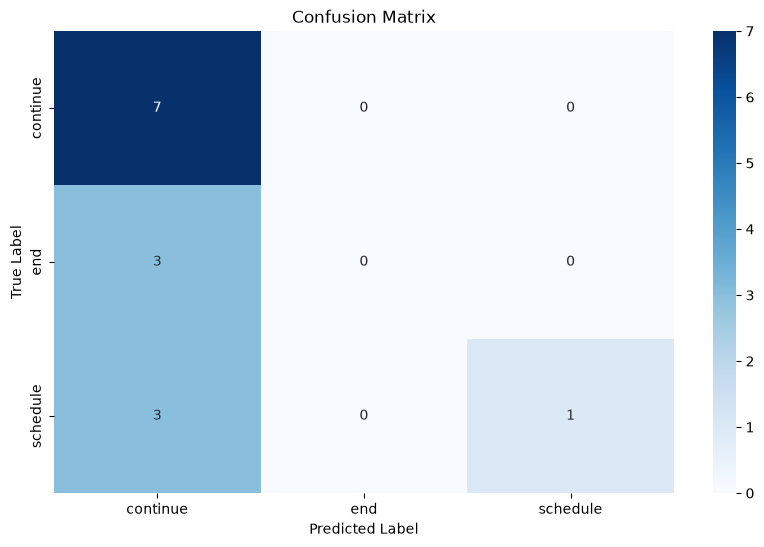

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.heatmap(df_cm, annot=True, fmt='d', cmap="Blues")
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.title('Confusion Matrix')
plt.show()

In [15]:
from datasets import load_dataset

train_data = load_dataset(
    "json",
    data_files="data/exit_advisor_train.jsonl",
    split="train"
)

print(train_data)

Generating train split: 136 examples [00:00, 6140.41 examples/s]

Dataset({
    features: ['messages'],
    num_rows: 136
})


### LoRA configuration

In [16]:
from peft import LoraConfig

peft_config = LoraConfig(
    r = 16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules="all-linear",
    task_type = "CAUSAL_LM"
)

print(peft_config)

LoraConfig(task_type='CAUSAL_LM', peft_type=<PeftType.LORA: 'LORA'>, auto_mapping=None, peft_version='0.21.0', base_model_name_or_path=None, revision=None, inference_mode=False, r=16, target_modules='all-linear', exclude_modules=None, lora_alpha=32, lora_dropout=0.05, fan_in_fan_out=False, bias='none', use_rslora=False, modules_to_save=None, init_lora_weights=True, layers_to_transform=None, layers_pattern=None, rank_pattern={}, alpha_pattern={}, megatron_config=None, megatron_core='megatron.core', trainable_token_indices=None, loftq_config={}, eva_config=None, corda_config=None, lora_ga_config=None, use_dora=False, velora_config=None, alora_invocation_tokens=None, use_qalora=False, qalora_group_size=16, monteclora_config=None, layer_replication=None, runtime_config=LoraRuntimeConfig(ephemeral_gpu_offload=False), lora_bias=False, target_parameters=None, use_bdlora=None, arrow_config=None, kasa_config=None, ensure_weight_tying=False)


In [17]:
from trl import SFTConfig

training_args = SFTConfig(
    output_dir="models/qwen-exit-advisor-lora-more-data",
    num_train_epochs=10,
    per_device_train_batch_size=4,
    learning_rate=2e-4, # 0.0002
    logging_steps=10,
    report_to="none",
    use_cpu=True,
    bf16=False,
)

## Training the Model
Fine-tune Qwen with LoRA on the training examples (10 epochs).

In [18]:
from trl import SFTTrainer

trainer = SFTTrainer(
    model=model_id,
    args=training_args,
    train_dataset=train_data,
    peft_config=peft_config,
)


trainer.train()

Truncating train dataset: 100%|██████████| 136/136 [00:00<00:00, 3058.07 examples/s]
Dropping fully masked examples from train dataset: 100%|██████████| 136/136 [00:00<00:00, 12269.32 examples/s]


{'loss': '1.663', 'grad_norm': '3.812', 'learning_rate': '0.0001947', 'entropy': '1.568', 'num_tokens': '4248', 'mean_token_accuracy': '0.6839', 'epoch': '0.2941'}
{'loss': '0.5259', 'grad_norm': '1.252', 'learning_rate': '0.0001888', 'entropy': '0.5686', 'num_tokens': '8626', 'mean_token_accuracy': '0.8672', 'epoch': '0.5882'}
{'loss': '0.4478', 'grad_norm': '1.732', 'learning_rate': '0.0001829', 'entropy': '0.4359', 'num_tokens': '1.318e+04', 'mean_token_accuracy': '0.8752', 'epoch': '0.8824'}
{'loss': '0.2949', 'grad_norm': '1.246', 'learning_rate': '0.0001771', 'entropy': '0.337', 'num_tokens': '1.74e+04', 'mean_token_accuracy': '0.908', 'epoch': '1.176'}
{'loss': '0.2978', 'grad_norm': '1.344', 'learning_rate': '0.0001712', 'entropy': '0.2767', 'num_tokens': '2.188e+04', 'mean_token_accuracy': '0.9116', 'epoch': '1.471'}
{'loss': '0.192', 'grad_norm': '0.3505', 'learning_rate': '0.0001653', 'entropy': '0.223', 'num_tokens': '2.592e+04', 'mean_token_accuracy': '0.9439', 'epoch': '1

TrainOutput(global_step=340, training_loss=0.1635051733430694, metrics={'train_runtime': 6086.0478, 'train_samples_per_second': 0.223, 'train_steps_per_second': 0.056, 'train_loss': 0.1635051733430694, 'epoch': 10.0})

In [4]:
from peft import AutoPeftModelForCausalLM
from transformers import AutoTokenizer

from pathlib import Path

lora_dir = "models/qwen-exit-advisor-lora-more-data"      # = output_dir in SFTConfig
my_fine_tuned_model = "models/qwen-exit-advisor-ft-more-data"

# the last checkpoint = the end of training (checkpoint-<number of steps>)
checkpoint = str(max(Path(lora_dir).glob("checkpoint-*"), key=lambda p: int(p.name.split("-")[1])))
print("using:", checkpoint)


# base model + LoRA adapter (from disk) -> merge into one normal model
merged_model = AutoPeftModelForCausalLM.from_pretrained(checkpoint).merge_and_unload()
merged_model.save_pretrained(my_fine_tuned_model)


tokenizer = AutoTokenizer.from_pretrained(model_id)
tokenizer.save_pretrained(my_fine_tuned_model)


print(my_fine_tuned_model)

using: models\qwen-exit-advisor-lora-more-data\checkpoint-340


Writing model shards: 100%|██████████| 1/1 [00:37<00:00, 37.07s/it]


models/qwen-exit-advisor-ft-more-data


In [29]:
import os

for f in os.listdir(my_fine_tuned_model):
    print(f)

chat_template.jinja
config.json
generation_config.json
model.safetensors
tokenizer.json
tokenizer_config.json


In [30]:
pipe_ft = pipeline("text-generation", model=my_fine_tuned_model, device_map="auto")

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 5916.90it/s]


In [31]:
y_pred_ft = []

for i, item in enumerate(test_examples):

    messages = item["messages"][:2]              # system + user (conversation history)

    output = pipe_ft(messages, max_new_tokens=5, do_sample=False)
    answer = output[0]["generated_text"][-1]["content"]

    y_pred_ft.append(normalize(answer))

    if i % 5 == 0:
        print(f"{i} / {len(test_examples)}")

print("Done")

0 / 14
5 / 14
10 / 14
Done


In [32]:
print("Base model accuracy:      ", f"{accuracy_score(y_true, y_pred):.2%}")
print("Fine-tuned model accuracy:", f"{accuracy_score(y_true, y_pred_ft):.2%}")

Base model accuracy:       57.14%
Fine-tuned model accuracy: 85.71%


In [36]:
labels_ft = sorted(set(y_true) | set(y_pred_ft))

cm_ft = confusion_matrix(y_true, y_pred_ft, labels=labels_ft)
df_cm_ft = pd.DataFrame(cm_ft, index=labels_ft, columns=labels_ft)

print("Confusion Matrix - fine-tuned:\n")
print(df_cm_ft)

Confusion Matrix - fine-tuned:

          continue  end  schedule
continue         5    0         2
end              0    3         0
schedule         0    0         4


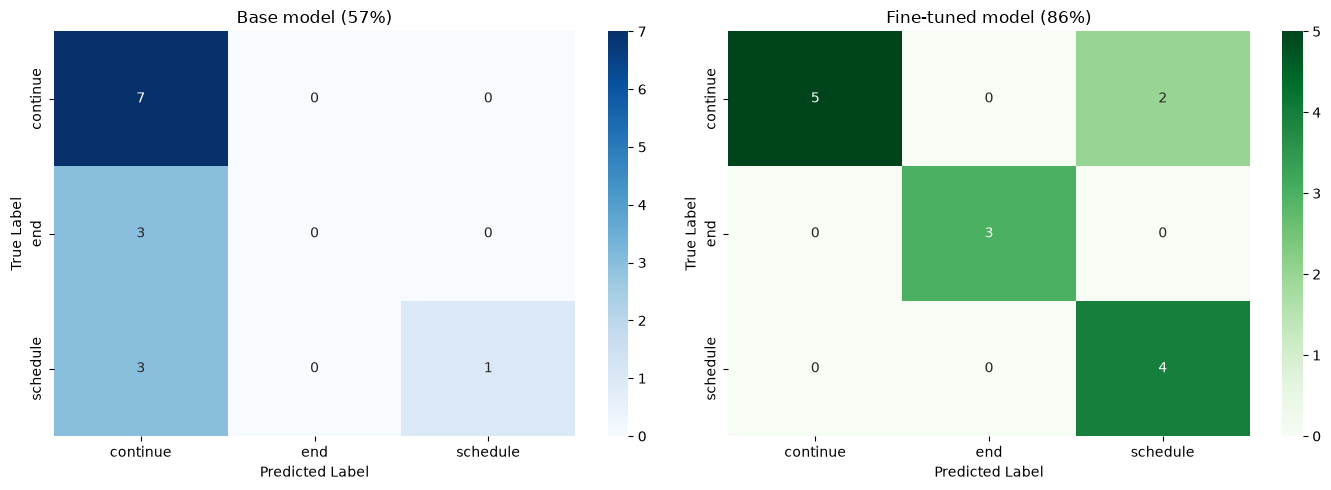

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(df_cm, annot=True, fmt='d', cmap="Blues", ax=axes[0])
axes[0].set_title(f"Base model ({accuracy_score(y_true, y_pred):.0%})")
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

sns.heatmap(df_cm_ft, annot=True, fmt='d', cmap="Greens", ax=axes[1])
axes[1].set_title(f"Fine-tuned model ({accuracy_score(y_true, y_pred_ft):.0%})")
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()

In [35]:
# Where did the fine-tuned model go wrong? (last candidate message = what the decision is based on)
for item, true, base, ft in zip(test_examples, y_true, y_pred, y_pred_ft):
    mark = "V" if ft == true else "X"
    last_line = item["messages"][1]["content"].split("\n")[-1]
    print(f"{mark}  correct: {true:9} | base: {base:9} | fine-tuned: {ft:9} | {last_line[:80]}")

V  correct: continue  | base: continue  | fine-tuned: continue  | (no messages yet - conversation start)
V  correct: schedule  | base: continue  | fine-tuned: schedule  | Candidate: I've been using Python professionally for five years, mostly for data
V  correct: schedule  | base: continue  | fine-tuned: schedule  | Candidate: I can't at that time—I'm busy.
V  correct: end       | base: continue  | fine-tuned: end       | Candidate: Monday at 3 PM is good.
V  correct: continue  | base: continue  | fine-tuned: continue  | (no messages yet - conversation start)
X  correct: continue  | base: continue  | fine-tuned: schedule  | Candidate: I have three years' experience with Django and Flask.
V  correct: continue  | base: continue  | fine-tuned: continue  | Candidate: Could you share more about the company's cloud technologies?
V  correct: schedule  | base: schedule  | fine-tuned: schedule  | Candidate: Sounds great! I'd be happy to schedule a meeting
V  correct: end       | base: continue 

## Push Model to the Hub

In [ ]:
import os
from dotenv import load_dotenv
from huggingface_hub import HfApi

load_dotenv()
hf_token=os.getenv("HF_TOKEN")      # the token is read from .env, not written in the code

your_username = HfApi(token=hf_token).whoami()["name"]

print(your_username)



c:\Users\sasha\Documents\קורס GenerativeAI\OpenAI\GenAIProject\hire-agent\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


sashabestie


In [6]:
merged_model.push_to_hub(f"{your_username}/qwen-exit-advisor", token=hf_token)
tokenizer.push_to_hub(f"{your_username}/qwen-exit-advisor", token=hf_token)

Writing model shards: 100%|██████████| 1/1 [00:24<00:00, 24.47s/it]
Processing Files (1 / 1): 100%|██████████|  988MB /  988MB, 12.3MB/s  
New Data Upload: 100%|██████████|  716MB /  716MB, 11.9MB/s  
c:\Users\sasha\Documents\קורס GenerativeAI\OpenAI\GenAIProject\hire-agent\.venv\Lib\site-packages\huggingface_hub\file_download.py:142: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\sasha\.cache\huggingface\hub\models--sashabestie--qwen-exit-advisor. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer 

CommitInfo(commit_url='https://huggingface.co/sashabestie/qwen-exit-advisor/commit/4ec9f64e308589c0d3d5a737e799a7fe173ce422', commit_message='Upload tokenizer', commit_description='', oid='4ec9f64e308589c0d3d5a737e799a7fe173ce422', pr_url=None, repo_url=RepoUrl('https://huggingface.co/sashabestie/qwen-exit-advisor', endpoint='https://huggingface.co', repo_type='model', repo_id='sashabestie/qwen-exit-advisor'), pr_revision=None, pr_num=None)